# ResNet from zero: the identity shortcut, the residual, and how backprop flows 🧱
### *Deep Residual Learning for Image Recognition* (He, Zhang, Ren, Sun - 2015), explained for a complete beginner

**The one-sentence idea:** instead of asking a stack of layers to learn the *whole* answer `H(x)`, we give them a shortcut that carries `x` straight through, and ask them to learn only the **difference** `F(x) = H(x) - x`. The output is `x + F(x)`.

That tiny `+ x` is the reason we can train networks with 50, 152, even 1000+ layers. This notebook shows *why*, one small step at a time. Every claim is checked by code - look for the `PASS` lines.

| step | question | what you will see |
|---|---|---|
| 1 | Why not just stack more layers? | the paper's "degradation" plot |
| 2 | Why is learning the *identity* hard for normal layers? | a measured experiment |
| 3 | What is a residual block? | the paper's diagram + 2 diagrams from the web, then 3 numbers traced by hand |
| 4 | How is the block written in code? | a real conv block, shapes, and a proof it starts as identity |
| 5 | How does the network "learn the residual"? | a 1-D toy: watch `F(x)` converge to the missing piece |
| 6 | How does backprop work through `x + F(x)`? | a worked example with real numbers and a graph |
| 7 | Why does the gradient survive 50 layers? | measured gradient size per layer |
| 8 | Does it really train deeper nets? | plain vs residual at depth 2 ... 40 |
| 9 | What if shapes change? | the projection shortcut (1x1 conv) |
| 10 | The real ResNet-18 / ResNet-50 | paper architecture figures + we build both and count parameters |
| 11 | Three ways to think about *why* it works | gradient highway, ensemble of paths, smooth loss surface |
| 12 | Cheat sheet, misconceptions, further reading | |

*Prerequisites:* you know a neural network is layers of "multiply by weights, add bias, apply ReLU", and that training = gradient descent using gradients from backpropagation. If "gradient" is fuzzy, step 6 rebuilds it from scratch. CPU only, ~1 minute to run.

*Figure credits:* figures marked **(paper)** are from the original papers (He et al. 2015; Veit et al. 2016; Li et al. 2018), reproduced here for teaching. The two web diagrams are from Wikimedia Commons (`ResBlock-stream.svg`, CC0) and *Dive into Deep Learning* (d2l.ai, Zhang, Lipton, Li, Smola; CC BY-SA 4.0).

In [1]:
import math, time, copy
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
PLAIN_C, RES_C, ID_C, GRAD_C = "#d9480f", "#1c7ed6", "#868e96", "#c2255c"   # one colour per idea, used everywhere

CHECKS = []
def check(name, ok, detail=""):
    """Record + print a PASS/FAIL line. Every claim in the notebook is backed by one of these."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

## Step 1 - The puzzle: deeper networks got *worse*

Common sense says: more layers = more capacity = better. In 2014-15 people stacked layers (VGG had 16-19) and it worked. But when the ResNet authors went further, something odd happened.

They trained a **20-layer** and a **56-layer** plain network (just conv layers stacked, no shortcuts) on CIFAR-10:

**(paper) Figure 1 - training error (left) and test error (right)**

<img src="resnet_assets/paper_fig1_degradation.png" width="620"/>

Look at the **left** plot, *training* error: the 56-layer net (red) is **worse than the 20-layer net (yellow) even on the data it is training on.**

This matters for a beginner:

* It is **not overfitting.** Overfitting means *low* training error but *high* test error. Here training error itself is higher.
* A 56-layer net could, in theory, copy the 20-layer net and make its extra 36 layers do *nothing* (pass the input through unchanged) - so it should be **at least as good**. It isn't. The optimizer (gradient descent) simply **fails to find** that solution.

The authors called this the **degradation problem**. The rest of this notebook is about the fix.

## Step 2 - Why is "do nothing" hard for a normal layer?

"Do nothing" = the **identity mapping**: output equals input, `H(x) = x`.

For a normal layer `y = ReLU(W x + b)`, doing nothing means gradient descent must land on **exactly `W = I` (the identity matrix) and `b = 0`** - out of millions of possible weight settings. And with 10 or 20 layers in a row, *every one* of them must land there simultaneously.

Compare with a **residual** layer `y = x + F(x)`. Doing nothing means `F(x) = 0`, i.e. **all weights of `F` equal 0**. Zero is the easiest value there is - it is where weight decay pulls, and we can simply *start* there.

Let us measure it. **Task: make a stack of 10 blocks reproduce its input** (`target = input`). The best possible answer is known to exist (identity), so any failure is purely an optimisation failure.

* *plain* block: `x -> ReLU( W2 . ReLU(W1 x) )`
* *residual* block: `x -> x + W2 . ReLU(W1 x)`  (same number of weights - only the `x +` differs)
* *residual, zero-init*: same, but `W2` starts at 0, so the network is *exactly* the identity at step 0.

plain                loss at step 0 =   0.4705    after 500 steps = 3.15e-01


residual             loss at step 0 =   0.5617    after 500 steps = 5.73e-04


residual, zero-init  loss at step 0 =   0.0000    after 500 steps = 0.00e+00


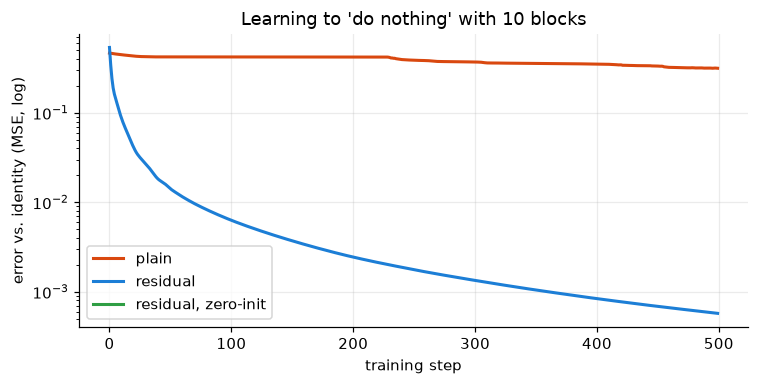

PASS  zero-init residual stack is EXACTLY the identity at step 0
PASS  residual learns identity far better than plain (>=10x lower error)   [plain 3.2e-01 vs residual 5.7e-04]


In [2]:
class MLPBlock(nn.Module):
    """Two weight layers F(x) = W2 relu(W1 x), used plain or with the shortcut. Same parameters either way."""
    def __init__(self, width, residual, zero_last=False, he_init=False):
        super().__init__()
        self.f1, self.f2, self.residual = nn.Linear(width, width), nn.Linear(width, width), residual
        if he_init:                                   # variance-preserving init for ReLU nets
            for l in (self.f1, self.f2): nn.init.kaiming_normal_(l.weight, nonlinearity="relu"); nn.init.zeros_(l.bias)
        if zero_last: nn.init.zeros_(self.f2.weight); nn.init.zeros_(self.f2.bias)   # F(x) = 0  => block = identity
    def forward(self, x):
        fx = self.f2(torch.relu(self.f1(x)))          # F(x): what the layers compute
        return x + fx if self.residual else torch.relu(fx)

def stack(depth, width, **kw): return nn.Sequential(*[MLPBlock(width, **kw) for _ in range(depth)])

def learn_identity(model, steps=500, lr=3e-3, width=16, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.relu(torch.randn(512, width, generator=g))      # non-negative, like activations after a ReLU
    opt, hist = torch.optim.Adam(model.parameters(), lr=lr), []
    for _ in range(steps):
        loss = F.mse_loss(model(x), x); opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    return hist

W, DEPTH = 16, 10
runs = {}
for name, kw in {"plain":               dict(residual=False),
                 "residual":            dict(residual=True),
                 "residual, zero-init": dict(residual=True, zero_last=True)}.items():
    torch.manual_seed(0); m = stack(DEPTH, W, **kw)
    x0 = torch.relu(torch.randn(512, W)); start = F.mse_loss(m(x0), x0).item()
    runs[name] = (learn_identity(m), start)
    print(f"{name:20s} loss at step 0 = {start:8.4f}    after 500 steps = {runs[name][0][-1]:.2e}")

fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, (h, _)), c in zip(runs.items(), [PLAIN_C, RES_C, "#2f9e44"]):
    ax.plot(h, label=name, color=c, lw=2)
ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_ylabel("error vs. identity (MSE, log)")
ax.set_title("Learning to 'do nothing' with 10 blocks"); ax.legend(); plt.tight_layout(); plt.show()

check("zero-init residual stack is EXACTLY the identity at step 0", runs["residual, zero-init"][1] == 0.0)
check("residual learns identity far better than plain (>=10x lower error)", runs["plain"][0][-1] > 10 * runs["residual"][0][-1],
      f"plain {runs['plain'][0][-1]:.1e} vs residual {runs['residual'][0][-1]:.1e}")

**Reading the plot:** the plain stack starts far from "do nothing" and has to *discover* it; the residual stack starts closer and gets there much faster; the zero-initialised one is already perfect at step 0. That is the **identity shortcut at work**: doing nothing is the *default*, and learning is only needed for whatever *extra* the task requires.

## Step 3 - The residual block

Let `x` be the input to a small group of layers, and `H(x)` the mapping we would like them to produce.

| | plain network | residual network |
|---|---|---|
| layers must learn | `H(x)` (everything) | `F(x) = H(x) - x` (just the *difference*) |
| output | `F(x)` | `F(x) + x` |

Rearranging `F(x) = H(x) - x` gives the famous formula **`output = x + F(x)`**. The `x` travels along a **skip connection** (also called *shortcut* or *identity connection*); `F(x)` is the **residual branch** - "residual" just means *what is left over* after you take `x` away.

**(paper) Figure 2 - "a building block"** &nbsp;&nbsp;|&nbsp;&nbsp; **(web, CC0) the same idea, redrawn**

<table><tr>
<td><img src="resnet_assets/paper_fig2_residual_block.png" width="330"/></td>
<td><img src="resnet_assets/web_resblock_stream.png" width="200"/></td>
</tr></table>

How to read them: the input `x` enters at the bottom. It splits in two. One copy goes **through the weight layers** (`F(x)`); the other copy **skips over them** untouched (the "identity"). They meet at the **⊕**, which simply *adds* them element by element.

**Intuition - editing vs. writing.** A plain layer is like writing a whole essay from a blank page every time. A residual block is like being handed the previous draft (`x`) and being asked only to *mark corrections* (`F(x)`). If the draft is already fine, the correct edit is "no change" = 0, which is trivial.

Here is the whole thing with three numbers, so nothing is hidden:

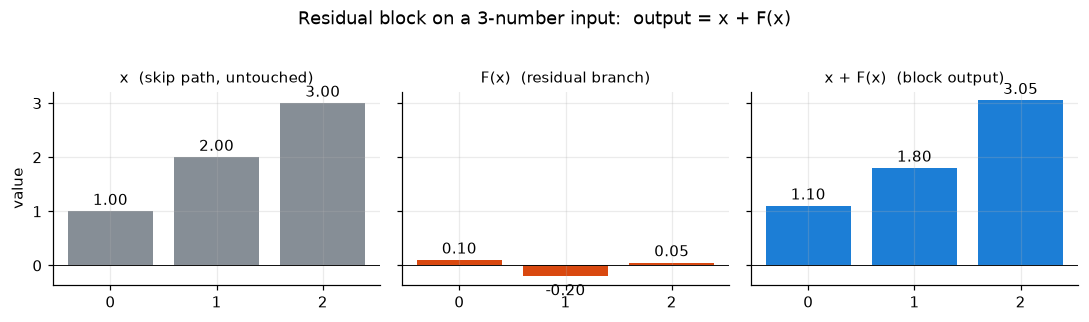

PASS  output = x + F(x) element-wise
Notice: the output is CLOSE to x. The block only nudged it. That is the whole point.


In [3]:
x  = torch.tensor([1.0, 2.0, 3.0])          # the input (the "draft")
Fx = torch.tensor([0.1, -0.2, 0.05])        # what the weight layers computed (the "corrections")
out = x + Fx                                 # the residual block output

fig, axs = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, v, t, c in zip(axs, [x, Fx, out], ["x  (skip path, untouched)", "F(x)  (residual branch)", "x + F(x)  (block output)"], [ID_C, PLAIN_C, RES_C]):
    ax.bar(range(3), v.numpy(), color=c); ax.set_title(t, fontsize=10); ax.set_xticks(range(3))
    for i, val in enumerate(v): ax.text(i, val + (0.12 if val >= 0 else -0.35), f"{val:.2f}", ha="center")
    ax.axhline(0, color="k", lw=0.6)
axs[0].set_ylabel("value"); plt.suptitle("Residual block on a 3-number input:  output = x + F(x)", y=1.03); plt.tight_layout(); plt.show()
check("output = x + F(x) element-wise", torch.allclose(out, torch.tensor([1.1, 1.8, 3.05])))
print("Notice: the output is CLOSE to x. The block only nudged it. That is the whole point.")

## Step 4 - The block as real code (the CNN version from the paper)

In an image network, `F(x)` is two 3x3 convolutions with BatchNorm and ReLU. The diagram below (from the *Dive into Deep Learning* book, CC BY-SA 4.0) shows every box. **Left:** the normal block. **Right:** the version with a **1x1 conv on the shortcut**, used when the shape changes (we cover that in Step 9).

<img src="resnet_assets/web_d2l_resnet_block.png" width="560"/>

Reading the left diagram bottom-to-top: `x` -> Conv3x3 -> BatchNorm -> ReLU -> Conv3x3 -> BatchNorm -> **(+ x)** -> ReLU. Everything inside the dashed box is `F(x)`; the arrow that bypasses the dashed box is the identity.

Now the code. Read `forward` - it is five lines.

In [4]:
class BasicBlock(nn.Module):
    """ResNet-18/34 block:  out = ReLU( F(x) + shortcut(x) ),  F = conv3x3-BN-ReLU-conv3x3-BN.

    shortcut(x) is the identity when input/output shapes match, otherwise a 1x1 conv (projection).
    zero_init_residual=True starts the last BN's scale (gamma) at 0, so F(x)=0 and the block begins as identity.
    """
    expansion = 1
    def __init__(self, in_ch, out_ch, stride=1, zero_init_residual=False):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(out_ch)
        if zero_init_residual: nn.init.zeros_(self.bn2.weight)
        self.shortcut = nn.Identity() if (stride == 1 and in_ch == out_ch) else \
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))
    def residual(self, x):                                   # F(x)
        return self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
    def forward(self, x):
        return F.relu(self.residual(x) + self.shortcut(x))   # <- the whole idea

blk = BasicBlock(64, 64).eval()
x = torch.randn(2, 64, 56, 56)
with torch.no_grad():
    fx, y = blk.residual(x), blk(x)
print("input x       :", tuple(x.shape))
print("F(x)  (branch):", tuple(fx.shape), "   <- must match x so we can add them")
print("output        :", tuple(y.shape))
check("block output == ReLU(x + F(x))", torch.allclose(y, F.relu(x + fx), atol=1e-6))

# Zero-init: F(x) = 0 exactly, so with a non-negative input (as after any ReLU) the block IS the identity.
zb = BasicBlock(64, 64, zero_init_residual=True).train()
xin = torch.relu(torch.randn(2, 64, 56, 56))
with torch.no_grad(): check("zero-init block returns its input unchanged (identity at step 0)", torch.allclose(zb(xin), xin))

input x       : (2, 64, 56, 56)
F(x)  (branch): (2, 64, 56, 56)    <- must match x so we can add them
output        : (2, 64, 56, 56)
PASS  block output == ReLU(x + F(x))
PASS  zero-init block returns its input unchanged (identity at step 0)


## Step 5 - How does the network "learn the residual"?

Nothing special happens in training - we do **not** tell the network what the residual is. We only write `out = x + F(x)` and train with the normal loss on `out`. Because the `x` is *already* in the output, the only way for the loss to drop is for `F` to supply **whatever `x` is missing**. So `F` automatically becomes `H(x) - x`.

Toy to see it: the true function is `H(x) = x + 0.3 sin(3x)`. The "big part" is `x` (the identity); the small missing piece is `0.3 sin(3x)`. We train `out = x + F(x)` where `F` is a tiny network that has never been told the answer.

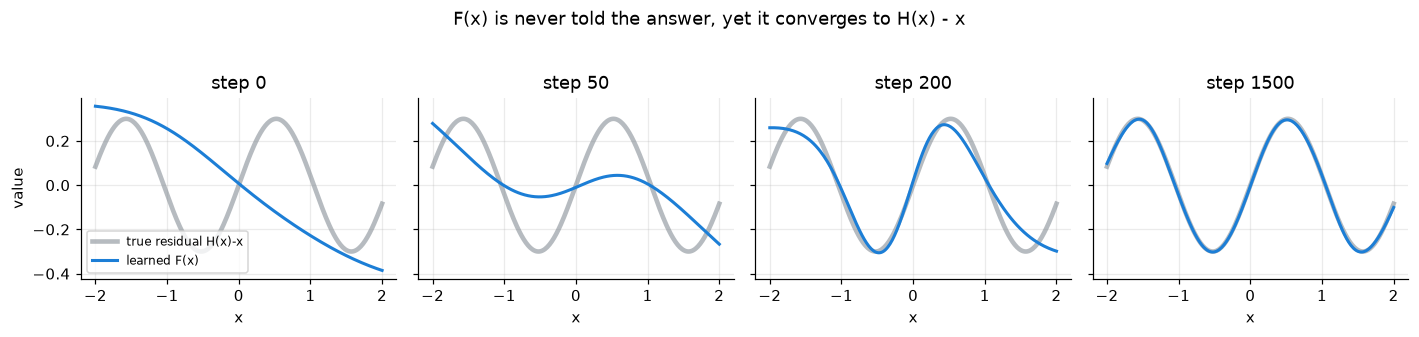

PASS  learned F(x) matches the true residual H(x)-x (max err < 0.05)   [max err 0.017]


PASS  target = identity  =>  F(x) is driven to ~0   [max |F| = 0.001]


In [5]:
torch.manual_seed(0)
H = lambda x: x + 0.3 * torch.sin(3 * x)                      # target mapping
true_residual = lambda x: 0.3 * torch.sin(3 * x)              # H(x) - x

class ResidualToy(nn.Module):
    def __init__(self):
        super().__init__(); self.F = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 1))
    def forward(self, x): return x + self.F(x)                 # the shortcut

net = ResidualToy(); opt = torch.optim.Adam(net.parameters(), lr=1e-2)
xs = torch.linspace(-2, 2, 256).unsqueeze(1)
snap, snaps_at = {}, [0, 50, 200, 1500]
for step in range(1501):
    if step in snaps_at: snap[step] = net.F(xs).detach().squeeze().clone()
    loss = F.mse_loss(net(xs), H(xs)); opt.zero_grad(); loss.backward(); opt.step()

fig, axs = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for ax, s in zip(axs, snaps_at):
    ax.plot(xs.squeeze(), true_residual(xs).squeeze(), color=ID_C, lw=3, alpha=.6, label="true residual H(x)-x")
    ax.plot(xs.squeeze(), snap[s], color=RES_C, lw=2, label="learned F(x)"); ax.set_title(f"step {s}"); ax.set_xlabel("x")
axs[0].legend(fontsize=8, loc="lower left"); axs[0].set_ylabel("value"); plt.suptitle("F(x) is never told the answer, yet it converges to H(x) - x", y=1.04); plt.tight_layout(); plt.show()

err = (net.F(xs) - true_residual(xs)).abs().max().item()
check("learned F(x) matches the true residual H(x)-x (max err < 0.05)", err < 0.05, f"max err {err:.3f}")

# And if the target is just the identity, the residual branch must collapse to 0:
net2 = ResidualToy(); opt2 = torch.optim.Adam(net2.parameters(), lr=1e-2)
for _ in range(1500):
    loss = F.mse_loss(net2(xs), xs); opt2.zero_grad(); loss.backward(); opt2.step()
check("target = identity  =>  F(x) is driven to ~0", net2.F(xs).abs().max().item() < 0.05, f"max |F| = {net2.F(xs).abs().max().item():.3f}")

**Takeaways**
1. **"Learning the residual" = learning the *correction*.** `F` converges to exactly `H(x) - x`.
2. If the best thing to do is nothing, `F` just shrinks to 0 (second check). A plain layer would have to *reconstruct* the identity.
3. The paper's hypothesis: for very deep nets, the ideal mapping is often *close* to the identity, so a small correction is far easier to find than the whole function from scratch.

## Step 6 - Backpropagation through `x + F(x)`

**Backprop in one paragraph.** To train, we need `dL/dw` (how the loss `L` changes when a weight `w` changes). Backprop gets it with the **chain rule**: go backwards through the network and *multiply* local derivatives. If `L` depends on `y`, and `y` depends on `x`, then

&nbsp;&nbsp;&nbsp;&nbsp;`dL/dx = dL/dy * dy/dx`.

**The addition node is the key.** For a block `y = x + F(x)`:

&nbsp;&nbsp;&nbsp;&nbsp;`dy/dx = d(x)/dx + dF/dx = 1 + F'(x)`

so

&nbsp;&nbsp;&nbsp;&nbsp;**`dL/dx = dL/dy * ( 1 + F'(x) )`**

An add operation just **copies the incoming gradient to both of its inputs**. One copy flows down the skip path *unchanged* (the `1`); the other goes through `F` (the `F'(x)` part). The gradient is therefore *never forced to pass through a long chain of weight matrices*.

Let us do a full worked example with real numbers, by hand **and** by PyTorch autograd, and compare:

* `x = 2`, branch `F(x) = w2 * ReLU(w1 * x)` with `w1 = 0.5`, `w2 = -0.3`
* output `y = x + F(x)`, loss `L = 0.5 * (y - t)^2` with target `t = 3`

In [6]:
# ----- forward + backward BY HAND -----
x_, w1_, w2_, t_ = 2.0, 0.5, -0.3, 3.0
a  = w1_ * x_                  # 1.0     pre-activation
r  = max(a, 0.0)               # 1.0     ReLU
Fx = w2_ * r                   # -0.3    residual branch
y  = x_ + Fx                   # 1.7     <- the add node
L  = 0.5 * (y - t_) ** 2       # 0.845

dL_dy  = y - t_                          # -1.3
dL_dFx = dL_dy * 1.0                     # add node copies the gradient to the branch ...
dL_dxskip = dL_dy * 1.0                  # ... and to the skip path (this is the "+1")
dL_dw2 = dL_dFx * r                      # -1.3
dL_dr  = dL_dFx * w2_                    # 0.39
dL_da  = dL_dr * (1.0 if a > 0 else 0.0) # ReLU passes gradient where it was active
dL_dw1 = dL_da * x_                      # 0.78
dL_dxbranch = dL_da * w1_                # gradient arriving at x through the branch
dL_dx  = dL_dxskip + dL_dxbranch         # x feeds TWO paths (skip + branch): their gradients ADD

# ----- same thing with autograd -----
x = torch.tensor(x_, requires_grad=True); w1 = torch.tensor(w1_, requires_grad=True); w2 = torch.tensor(w2_, requires_grad=True)
y_t = x + w2 * torch.relu(w1 * x); L_t = 0.5 * (y_t - t_) ** 2; L_t.backward()

print(f"{'quantity':10s} {'by hand':>10s} {'autograd':>10s}")
for n, h, a_ in [("dL/dx", dL_dx, x.grad.item()), ("dL/dw1", dL_dw1, w1.grad.item()), ("dL/dw2", dL_dw2, w2.grad.item())]:
    print(f"{n:10s} {h:10.4f} {a_:10.4f}")
check("hand-derived gradients equal autograd (dL/dx, dL/dw1, dL/dw2)",
      all(abs(h - a_) < 1e-6 for h, a_ in [(dL_dx, x.grad.item()), (dL_dw1, w1.grad.item()), (dL_dw2, w2.grad.item())]))
check("dL/dx = dL/dy * (1 + F'(x))   with F'(x) = w2*w1 here",
      abs(dL_dx - dL_dy * (1 + w2_ * w1_)) < 1e-9, f"{dL_dy:.2f} * (1 + {w2_*w1_:.2f}) = {dL_dy*(1+w2_*w1_):.4f}")

quantity      by hand   autograd
dL/dx         -1.1050    -1.1050
dL/dw1         0.7800     0.7800
dL/dw2        -1.3000    -1.3000
PASS  hand-derived gradients equal autograd (dL/dx, dL/dw1, dL/dw2)
PASS  dL/dx = dL/dy * (1 + F'(x))   with F'(x) = w2*w1 here   [-1.30 * (1 + -0.15) = -1.1050]


Now the same example as a picture: **blue = forward values, red = gradients flowing backwards.** Watch the red number at the ⊕ get *copied* onto both outgoing branches.

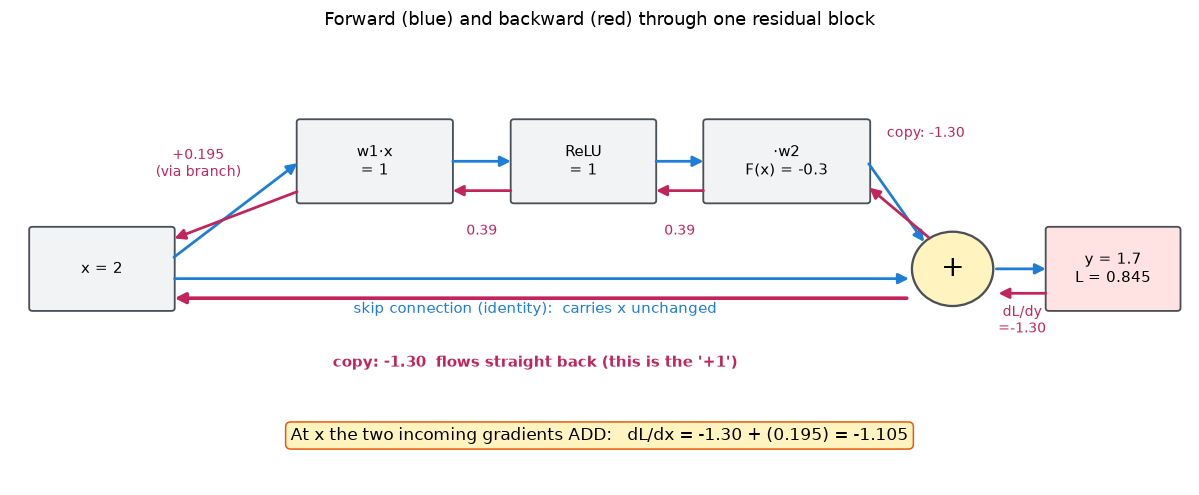

PASS  gradient at x = skip-path copy + branch gradient


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6)); ax.set_xlim(0, 11); ax.set_ylim(0, 4.6); ax.axis("off"); ax.grid(False)
def box(xy, w, h, txt, fc="#f1f3f5"):
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.03", fc=fc, ec="#495057", lw=1.2)); ax.text(xy[0]+w/2, xy[1]+h/2, txt, ha="center", va="center", fontsize=10)
def arr(p, q, c, rad=0.0, lw=1.8): ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=14, color=c, lw=lw, connectionstyle=f"arc3,rad={rad}"))
fw, bw = RES_C, GRAD_C
box((0.2, 1.8), 1.3, 0.8, f"x = {x_:g}")
box((2.7, 2.9), 1.4, 0.8, f"w1·x\n= {a:g}"); box((4.7, 2.9), 1.3, 0.8, f"ReLU\n= {r:g}"); box((6.5, 2.9), 1.5, 0.8, f"·w2\nF(x) = {Fx:g}")
ax.add_patch(Circle((8.8, 2.2), 0.38, fc="#fff3bf", ec="#495057", lw=1.5)); ax.text(8.8, 2.2, "+", ha="center", va="center", fontsize=18)
box((9.7, 1.8), 1.2, 0.8, f"y = {y:g}\nL = {L:.3f}", "#ffe3e3")
arr((1.5, 2.3), (2.7, 3.3), fw); arr((4.1, 3.3), (4.7, 3.3), fw); arr((6.0, 3.3), (6.5, 3.3), fw); arr((8.0, 3.3), (8.55, 2.45), fw)
arr((1.5, 2.1), (8.42, 2.1), fw, rad=0.0); ax.text(4.9, 1.75, "skip connection (identity):  carries x unchanged", ha="center", color=fw, fontsize=10)
arr((9.18, 2.2), (9.7, 2.2), fw)
# gradients (red), drawn slightly offset
arr((9.7, 1.95), (9.2, 1.95), bw); ax.text(9.45, 1.55, f"dL/dy\n={dL_dy:.2f}", color=bw, ha="center", fontsize=9)
arr((8.6, 2.5), (8.0, 3.05), bw); ax.text(8.55, 3.55, f"copy: {dL_dFx:.2f}", color=bw, ha="center", fontsize=9)
arr((8.4, 1.9), (1.5, 1.9), bw, lw=2.4); ax.text(4.9, 1.2, f"copy: {dL_dxskip:.2f}  flows straight back (this is the '+1')", color=bw, ha="center", fontsize=10, fontweight="bold")
arr((6.5, 3.0), (6.0, 3.0), bw); ax.text(6.25, 2.55, f"{dL_dr:.2f}", color=bw, ha="center", fontsize=9)
arr((4.7, 3.0), (4.1, 3.0), bw); ax.text(4.4, 2.55, f"{dL_da:.2f}", color=bw, ha="center", fontsize=9)
arr((2.7, 3.0), (1.5, 2.5), bw); ax.text(1.75, 3.15, f"+{dL_dxbranch:.3f}\n(via branch)", color=bw, ha="center", fontsize=9)
ax.text(5.5, 0.45, f"At x the two incoming gradients ADD:   dL/dx = {dL_dxskip:.2f} + ({dL_dxbranch:.3f}) = {dL_dx:.3f}", ha="center", fontsize=11, bbox=dict(fc="#fff3bf", ec="#e8590c", boxstyle="round"))
ax.set_title("Forward (blue) and backward (red) through one residual block", fontsize=12); plt.tight_layout(); plt.show()
check("gradient at x = skip-path copy + branch gradient", abs(dL_dx - (dL_dxskip + dL_dxbranch)) < 1e-9)

### Stacking many blocks - the "gradient highway"

Write block `i` as `x_{i+1} = x_i + F_i(x_i)`. Unrolling `L` blocks gives

&nbsp;&nbsp;&nbsp;&nbsp;`x_L = x_l + F_l(x_l) + F_{l+1}(x_{l+1}) + ... + F_{L-1}(x_{L-1})`  &nbsp;&nbsp;&nbsp;(x_l plus a **sum** of corrections)

and so

&nbsp;&nbsp;&nbsp;&nbsp;`dLoss/dx_l = dLoss/dx_L * ( 1 + d/dx_l [ F_l + ... + F_{L-1} ] )`

The `1` means a piece of the gradient reaches *any* earlier block **directly from the loss**, no matter how deep the net is. In a **plain** network the same gradient is a *product* of `L` Jacobians (one per layer):

&nbsp;&nbsp;&nbsp;&nbsp;`dLoss/dx_l = dLoss/dx_L * J_{L-1} * J_{L-2} * ... * J_l`

and a product of many numbers that are mostly < 1 shrinks exponentially (**vanishing gradients**); if they are mostly > 1 it explodes. *Sum* (residual) vs. *product* (plain) - that is the whole difference. Next we measure it.

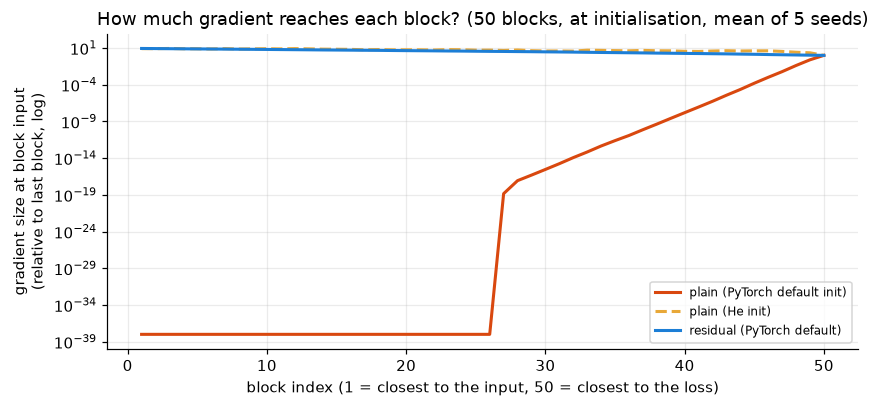

plain (PyTorch default init)   gradient at block 1 / gradient at block 50 = 0.00e+00
plain (He init)                gradient at block 1 / gradient at block 50 = 8.30e+00
residual (PyTorch default)     gradient at block 1 / gradient at block 50 = 8.73e+00
PASS  plain net (default init): gradient at the first block is >1000x smaller than at the last
PASS  residual net: gradient at the first block stays within 100x of the last (no collapse)


In [8]:
def grad_profile(depth, width, seed, **kw):
    """Gradient norm at the INPUT of every block (relative to the last block), at initialisation."""
    torch.manual_seed(seed)
    m = stack(depth, width, **kw); h = torch.randn(256, width); acts = []
    for b in m:
        h = b(h); h.retain_grad(); acts.append(h)
    (h.pow(2).mean()).backward()
    g = torch.tensor([a.grad.norm().item() for a in acts])
    return (g / g[-1]).numpy()                 # index 0 = earliest block, last = 1.0

DEPTH, WIDTH = 50, 64
variants = {"plain (PyTorch default init)": dict(residual=False),
            "plain (He init)":             dict(residual=False, he_init=True),
            "residual (PyTorch default)":  dict(residual=True)}
prof = {k: np.mean([grad_profile(DEPTH, WIDTH, s, **kw) for s in range(5)], 0) for k, kw in variants.items()}

fig, ax = plt.subplots(figsize=(8, 3.8))
FLOOR = 1e-38                                 # float32 underflow shows up as exact 0; clip so it can be drawn on a log axis
for (k, v), c, ls in zip(prof.items(), [PLAIN_C, "#e8a838", RES_C], ["-", "--", "-"]): ax.plot(range(1, DEPTH + 1), np.maximum(v, FLOOR), color=c, lw=2, ls=ls, label=k)
ax.set_yscale("log"); ax.set_xlabel("block index (1 = closest to the input, 50 = closest to the loss)")
ax.set_ylabel("gradient size at block input\n(relative to last block, log)"); ax.set_title("How much gradient reaches each block? (50 blocks, at initialisation, mean of 5 seeds)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
for k, v in prof.items(): print(f"{k:30s} gradient at block 1 / gradient at block 50 = {v[0]:.2e}")

check("plain net (default init): gradient at the first block is >1000x smaller than at the last", prof["plain (PyTorch default init)"][0] < 1e-3)
check("residual net: gradient at the first block stays within 100x of the last (no collapse)", 1e-2 < prof["residual (PyTorch default)"][0] < 1e2)

**What the plot says**

* **Plain, default init (red-orange):** the gradient shrinks so fast going backwards that after 50 blocks it has underflowed to **exactly 0** in float32 (the line drops to the floor of the plot). The earliest layers receive *no* learning signal. This is the textbook vanishing gradient.
* **Plain, He init (dashed):** careful initialisation (and, in real ResNets, **BatchNorm**) *fixes* the vanishing gradient **at initialisation** - the dashed line is flat, no collapse. This is an important honesty point: the ResNet paper says exactly this - for their plain nets *with BatchNorm* the gradients were healthy, **yet the degradation problem remained**. So the shortcut is not *only* about gradient size; it also changes **what is easy to represent** (identity = zero) and the **shape of the optimisation problem** (Step 11).
* **Residual (blue):** stays in a healthy band with *no* special initialisation - the `+1` provides a guaranteed path.

## Step 8 - Does it actually train deeper networks? (the degradation experiment, in miniature)

We reproduce the paper's Figure 1 / Figure 4 story on a toy: classify points on **3 intertwined spirals** with MLPs of increasing depth. Same width, same optimiser, same number of steps; the **only** difference is the `x +`.

depth (blocks)               1       2       5      10      20      40
plain (default init)  train acc    1.00    1.00    0.53    0.33    0.33    0.33
plain (He init)  train acc    1.00    1.00    1.00    1.00    0.33    0.37
residual  train acc       1.00    1.00    1.00    1.00    1.00    1.00


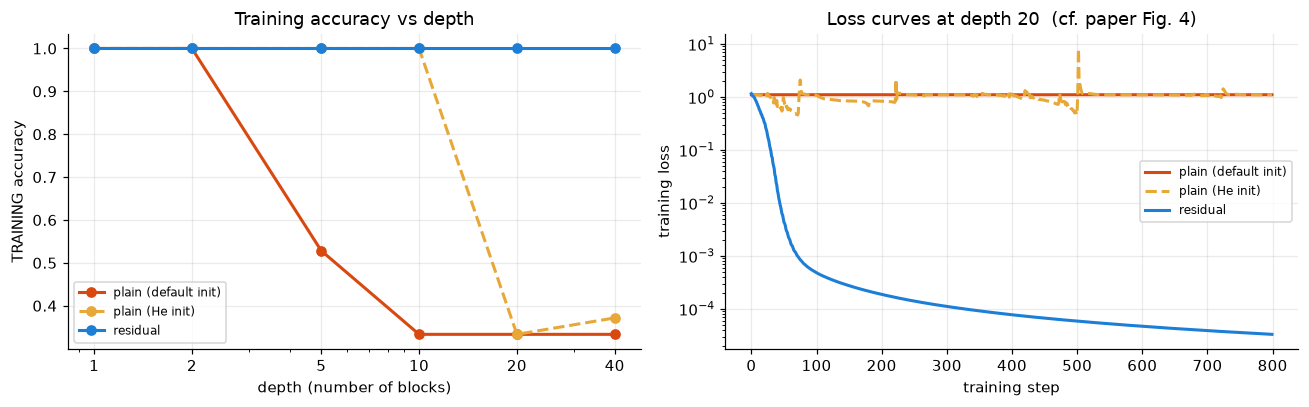

PASS  residual nets train well at EVERY depth (train acc >= 0.99 up to depth 40)
PASS  plain (default init) collapses at depth >= 10 (train acc < 0.7)
PASS  even with healthy He-init gradients, the plain net still degrades with depth (acc @40 < acc @10)   [depth 10: 1.00 -> depth 40: 0.37]


In [9]:
def spiral(n=600, k=3, noise=0.15, seed=0):
    g = torch.Generator().manual_seed(seed); X, Y = [], []
    for c in range(k):
        t = torch.linspace(0.2, 1, n // k); ang = t * 4 + c * 2 * math.pi / k
        X.append(torch.stack([t * torch.cos(ang), t * torch.sin(ang)], 1) + noise * 0.3 * torch.randn(n // k, 2, generator=g)); Y += [c] * (n // k)
    return torch.cat(X), torch.tensor(Y)
Xs, Ys = spiral()

class DeepNet(nn.Module):
    def __init__(self, depth, residual, he_init=False, width=32):
        super().__init__(); self.inp = nn.Linear(2, width)
        self.blocks = stack(depth, width, residual=residual, he_init=he_init); self.out = nn.Linear(width, 3)
    def forward(self, x): return self.out(self.blocks(torch.relu(self.inp(x))))

def train(depth, residual, he_init=False, steps=800, lr=0.02):
    torch.manual_seed(1); m = DeepNet(depth, residual, he_init); opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9); hist = []
    for _ in range(steps):
        loss = F.cross_entropy(m(Xs), Ys); opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    acc = (m(Xs).argmax(1) == Ys).float().mean().item()
    return m, hist, acc

depths = [1, 2, 5, 10, 20, 40]
cfgs = {"plain (default init)": dict(residual=False), "plain (He init)": dict(residual=False, he_init=True), "residual": dict(residual=True)}
res, models = {}, {}
for name, kw in cfgs.items():
    res[name] = []
    for d in depths:
        m, h, acc = train(d, **kw); res[name].append((h, acc)); models[(name, d)] = m
print(f"{'depth (blocks)':22s}" + "".join(f"{d:>8d}" for d in depths))
for name in cfgs: print(f"{name + '  train acc':22s}" + "".join(f"{a:8.2f}" for _, a in res[name]))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for (name, r), c, ls in zip(res.items(), [PLAIN_C, "#e8a838", RES_C], ["-", "--", "-"]):
    axs[0].plot(depths, [a for _, a in r], "o", color=c, ls=ls, lw=2, label=name)
    axs[1].plot(r[depths.index(20)][0], color=c, ls=ls, lw=2, label=name)
axs[0].set_xscale("log"); axs[0].set_xticks(depths); axs[0].set_xticklabels(depths); axs[0].set_xlabel("depth (number of blocks)"); axs[0].set_ylabel("TRAINING accuracy")
axs[0].set_title("Training accuracy vs depth"); axs[0].legend(fontsize=8)
axs[1].set_xlabel("training step"); axs[1].set_ylabel("training loss"); axs[1].set_title("Loss curves at depth 20  (cf. paper Fig. 4)"); axs[1].set_yscale("log"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

acc = {n: dict(zip(depths, [a for _, a in r])) for n, r in res.items()}
check("residual nets train well at EVERY depth (train acc >= 0.99 up to depth 40)", all(acc["residual"][d] >= 0.99 for d in depths))
check("plain (default init) collapses at depth >= 10 (train acc < 0.7)", all(acc["plain (default init)"][d] < 0.7 for d in [10, 20, 40]))
check("even with healthy He-init gradients, the plain net still degrades with depth (acc @40 < acc @10)", acc["plain (He init)"][40] < acc["plain (He init)"][10] - 0.3,
      f"depth 10: {acc['plain (He init)'][10]:.2f} -> depth 40: {acc['plain (He init)'][40]:.2f}")

**Reading it:** at depth 1-2 everything works. As depth grows, the plain nets' *training* accuracy **collapses** (to ~0.33, i.e. guessing among 3 classes) - the same *deeper-is-worse-on-training-data* pattern as the paper's Figure 1 - while the residual net fits perfectly at every depth.

The **orange dashed** line is the important one. It is a plain net with He initialisation, whose gradients at step 0 were perfectly healthy (Step 7). It trains fine up to 10 blocks, then **still fails at 20 and 40**. So "just fix the gradient size" does not remove degradation - exactly the paper's point. (Our toy has no BatchNorm; see the honest note below.)

Now compare the paper's real-data version of this experiment, on **ImageNet** (left: plain-18 vs plain-34; right: ResNet-18 vs ResNet-34). Thin lines = training error, bold = validation error:

**(paper) Figure 4**

<img src="resnet_assets/paper_fig4_imagenet_curves.png" width="760"/>

Left: the deeper plain net (34, red) has *higher* error than the shallower one (18, cyan) - degradation. Right: with shortcuts the order **flips** - ResNet-34 (red) beats ResNet-18 (cyan). Depth finally helps.

> **Honest note on the toy:** these are *ReLU-only, no-BatchNorm* MLPs trained with plain SGD, which are more fragile than the paper's plain CNNs, so our plain curves fail more dramatically (to chance) than the paper's (a few points of extra error). The qualitative lesson - residual nets keep training as depth grows, plain nets do not - is the same.

## Step 9 - What if the shapes don't match? (projection shortcut)

`x + F(x)` needs `x` and `F(x)` to have the **same shape**. Between stages, ResNet halves the spatial size (stride 2) and doubles the channels, so `F(x)` changes shape but a bare `x` does not. The paper's fix (Eq. 2, "option B"): apply a **1x1 convolution** to the shortcut so it matches. It is drawn as the right-hand block in the d2l diagram of Step 4. The identity shortcut is used everywhere else, because it adds **zero** parameters and zero compute.

In [10]:
down = BasicBlock(64, 128, stride=2).eval()          # shape CHANGES: 64ch@56x56  ->  128ch@28x28
x = torch.randn(1, 64, 56, 56)
with torch.no_grad(): fx, sc, y = down.residual(x), down.shortcut(x), down(x)
print("x          :", tuple(x.shape))
print("F(x)       :", tuple(fx.shape))
print("shortcut(x):", tuple(sc.shape), "  <- 1x1 conv (stride 2) reshaped x to match F(x)")
print("output     :", tuple(y.shape))
check("shortcut(x) and F(x) shapes match, so they can be added", sc.shape == fx.shape)
n_id, n_proj = sum(p.numel() for p in BasicBlock(64, 64).shortcut.parameters()), sum(p.numel() for p in down.shortcut.parameters())
check("identity shortcut has 0 parameters; projection has some", n_id == 0 and n_proj > 0, f"identity {n_id}, projection {n_proj:,}")

x          : (1, 64, 56, 56)
F(x)       : (1, 128, 28, 28)
shortcut(x): (1, 128, 28, 28)   <- 1x1 conv (stride 2) reshaped x to match F(x)
output     : (1, 128, 28, 28)
PASS  shortcut(x) and F(x) shapes match, so they can be added
PASS  identity shortcut has 0 parameters; projection has some   [identity 0, projection 8,448]


## Step 10 - The full network: ResNet-18 ... ResNet-152

Stack the blocks in four **stages** (channels 64 -> 128 -> 256 -> 512), start with a 7x7 conv and max-pool, finish with global average pooling and one linear layer.

**(paper) Figure 3 - left: VGG-19; middle: a 34-layer *plain* net; right: the 34-layer *residual* net.** Solid curved arrows are identity shortcuts; **dotted** ones are the projection (1x1 conv) shortcuts where the shape changes.

<img src="resnet_assets/paper_fig3_architectures.png" width="330"/>

For networks of 50+ layers the paper switches to the cheaper **bottleneck** block: a 1x1 conv *squeezes* the channels, a 3x3 conv works on the small tensor, a 1x1 conv *expands* back. **(paper) Figure 5** - left: the basic block (ResNet-34), right: the bottleneck (ResNet-50/101/152):

<img src="resnet_assets/paper_fig5_bottleneck.png" width="420"/>

Now we build them ourselves. Sanity check: parameter counts must match the well-known figures for ResNet-18 (**11,689,512**) and ResNet-50 (**25,557,032**) with a 1000-class head.

In [11]:
class Bottleneck(nn.Module):
    """ResNet-50/101/152 block:  1x1 (reduce) -> 3x3 -> 1x1 (expand x4),  + shortcut."""
    expansion = 4
    def __init__(self, in_ch, mid_ch, stride=1, zero_init_residual=False):
        super().__init__(); out_ch = mid_ch * 4
        self.conv1 = nn.Conv2d(in_ch, mid_ch, 1, bias=False);              self.bn1 = nn.BatchNorm2d(mid_ch)
        self.conv2 = nn.Conv2d(mid_ch, mid_ch, 3, stride, 1, bias=False);  self.bn2 = nn.BatchNorm2d(mid_ch)
        self.conv3 = nn.Conv2d(mid_ch, out_ch, 1, bias=False);             self.bn3 = nn.BatchNorm2d(out_ch)
        if zero_init_residual: nn.init.zeros_(self.bn3.weight)
        self.shortcut = nn.Identity() if (stride == 1 and in_ch == out_ch) else \
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))
    def forward(self, x):
        f = self.bn3(self.conv3(F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x))))))))
        return F.relu(f + self.shortcut(x))

class ResNet(nn.Module):
    """Generic ResNet: stem -> 4 stages of residual blocks -> global pool -> linear."""
    def __init__(self, block, layers, num_classes=1000, zero_init_residual=False):
        super().__init__(); self.in_ch = 64
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 7, 2, 3, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(3, 2, 1))
        self.stages = nn.Sequential(*[self._stage(block, w, n, 1 if i == 0 else 2, zero_init_residual) for i, (w, n) in enumerate(zip([64, 128, 256, 512], layers))])
        self.fc = nn.Linear(512 * block.expansion, num_classes)
        for m in self.modules():                                   # He init for convs
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def _stage(self, block, width, n, stride, zero_init):
        blocks = []
        for i in range(n):
            blocks.append(block(self.in_ch, width, stride if i == 0 else 1, zero_init_residual=zero_init)); self.in_ch = width * block.expansion
        return nn.Sequential(*blocks)
    def forward(self, x): return self.fc(torch.flatten(F.adaptive_avg_pool2d(self.stages(self.stem(x)), 1), 1))

resnet18 = lambda **kw: ResNet(BasicBlock, [2, 2, 2, 2], **kw)
resnet34 = lambda **kw: ResNet(BasicBlock, [3, 4, 6, 3], **kw)
resnet50 = lambda **kw: ResNet(Bottleneck, [3, 4, 6, 3], **kw)

nparams = lambda m: sum(p.numel() for p in m.parameters())
r18, r50 = resnet18(), resnet50()
print(f"ResNet-18 params: {nparams(r18):,}\nResNet-50 params: {nparams(r50):,}")
check("ResNet-18 has 11,689,512 parameters (reference value)", nparams(r18) == 11_689_512)
check("ResNet-50 has 25,557,032 parameters (reference value)", nparams(r50) == 25_557_032)
with torch.no_grad(): out = r18.eval()(torch.randn(2, 3, 224, 224))
check("forward pass on 2 x 3 x 224 x 224 -> 2 x 1000 logits", tuple(out.shape) == (2, 1000))

# where does the '18' come from?  1 stem conv + (2+2+2+2) blocks x 2 convs + 1 fc = 18 weight layers
n_conv_fc = 1 + sum(2 * n for n in [2, 2, 2, 2]) + 1
check("'18' = 1 stem conv + 16 block convs + 1 fc", n_conv_fc == 18)

ResNet-18 params: 11,689,512
ResNet-50 params: 25,557,032
PASS  ResNet-18 has 11,689,512 parameters (reference value)
PASS  ResNet-50 has 25,557,032 parameters (reference value)
PASS  forward pass on 2 x 3 x 224 x 224 -> 2 x 1000 logits
PASS  '18' = 1 stem conv + 16 block convs + 1 fc


In [12]:
# Walk one image through ResNet-18 and print the shape after every stage - this is the "feature pyramid".
x = torch.randn(1, 3, 224, 224); r18.eval()
with torch.no_grad():
    h = r18.stem(x); print(f"{'stem':8s} -> {tuple(h.shape)}")
    for i, st in enumerate(r18.stages, 1):
        for j, b in enumerate(st): h = b(h); print(f"stage{i} block{j+1}: {tuple(h.shape)}" + ("   <- projection shortcut here" if not isinstance(b.shortcut, nn.Identity) else ""))

stem     -> (1, 64, 56, 56)
stage1 block1: (1, 64, 56, 56)
stage1 block2: (1, 64, 56, 56)
stage2 block1: (1, 128, 28, 28)   <- projection shortcut here
stage2 block2: (1, 128, 28, 28)
stage3 block1: (1, 256, 14, 14)   <- projection shortcut here
stage3 block2: (1, 256, 14, 14)
stage4 block1: (1, 512, 7, 7)   <- projection shortcut here
stage4 block2: (1, 512, 7, 7)


## Step 11 - Three mental models for *why* it works

### (a) A gradient highway  *(Step 6-7)*
The `+1` gives every layer a direct line to the loss. Sum instead of product.

### (b) An ensemble of many shallow networks
Unroll three blocks: `x3 = (1+F1)(1+F2)(1+F3) x` (writing `F_i` as an operator). Multiply it out and you get **8 = 2^3 terms** - 8 different *paths* from input to output, each path either takes a block's `F` or skips it. Veit, Wilber & Belongie (2016) drew exactly this:

**(paper, Veit et al. 2016) Fig. 1 - left: how we usually draw a residual net; right: the same net "unraveled" into 2^n paths**

<img src="resnet_assets/paper_veit_unraveled.png" width="620"/>

Most of those paths are *short* (a binomial distribution of lengths), so a 110-layer ResNet behaves like a bag of mostly-shallow networks, which are easy to train. Let us verify the path-counting identity numerically, then do their "lesion" test: **delete** one block from a trained network.

n= 3 blocks:  2^n =     8 paths   stack output = +1.310521   sum of paths = +1.310521
n= 6 blocks:  2^n =    64 paths   stack output = +1.435562   sum of paths = +1.435562
n=10 blocks:  2^n =  1024 paths   stack output = -0.006595   sum of paths = -0.006595
PASS  residual stack == sum over all 2^n paths


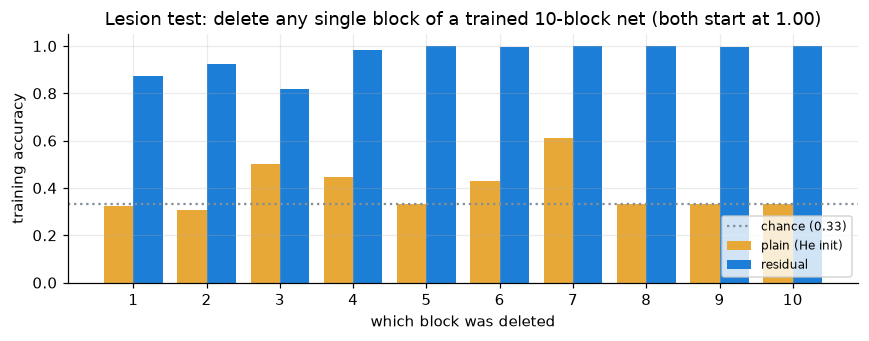

plain (He init)  worst single-block deletion -> accuracy 0.31   mean 0.40
residual         worst single-block deletion -> accuracy 0.82   mean 0.96
PASS  residual net is more robust to deleting a block than the plain net (mean accuracy)   [0.96 vs 0.40]


In [13]:
# Path-counting identity: for linear branches f_i(x) = a_i * x,  prod(1 + a_i) = sum over all 2^n subsets of prod(a_i in subset)
import itertools
rng = np.random.default_rng(0); ok = True
for n in [3, 6, 10]:
    a = rng.normal(0, 0.5, n)
    stacked = np.prod(1 + a)                                                # run the residual stack
    paths = sum(np.prod([a[i] for i in S]) for r in range(n + 1) for S in itertools.combinations(range(n), r))  # sum of 2^n paths
    ok &= np.isclose(stacked, paths); print(f"n={n:2d} blocks:  2^n = {2**n:5d} paths   stack output = {stacked:+.6f}   sum of paths = {paths:+.6f}")
check("residual stack == sum over all 2^n paths", ok)

# Lesion test: delete ONE block from a trained 10-block network and re-measure training accuracy.
def acc_without(model, k):
    probe = copy.deepcopy(model); probe.blocks = nn.Sequential(*[b for i, b in enumerate(model.blocks) if i != k])
    with torch.no_grad(): return (probe(Xs).argmax(1) == Ys).float().mean().item()
LD = 10
rows = {"plain (He init)": models[("plain (He init)", LD)], "residual": models[("residual", LD)]}
drops = {n: [acc_without(m, k) for k in range(LD)] for n, m in rows.items()}
fig, ax = plt.subplots(figsize=(8, 3.2)); w = 0.4
for j, (n, c) in enumerate(zip(rows, ["#e8a838", RES_C])): ax.bar(np.arange(1, LD + 1) + (j - .5) * w, drops[n], w, color=c, label=n)
ax.axhline(1 / 3, color=ID_C, ls=":", label="chance (0.33)"); ax.set_ylim(0, 1.05); ax.set_xticks(range(1, LD + 1))
ax.set_xlabel("which block was deleted"); ax.set_ylabel("training accuracy"); ax.set_title("Lesion test: delete any single block of a trained 10-block net (both start at 1.00)"); ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()
for n in rows: print(f"{n:16s} worst single-block deletion -> accuracy {min(drops[n]):.2f}   mean {np.mean(drops[n]):.2f}")
check("residual net is more robust to deleting a block than the plain net (mean accuracy)", np.mean(drops["residual"]) > np.mean(drops["plain (He init)"]),
      f"{np.mean(drops['residual']):.2f} vs {np.mean(drops['plain (He init)']):.2f}")

**What we measured:** deleting a single block of the trained residual net leaves accuracy at 0.82-1.00 (mean 0.96), while the same surgery on the plain net drops it to about chance (mean 0.40). Veit et al. found the same on real ImageNet ResNets: removing one block barely changes accuracy, whereas deleting one layer from a plain VGG-style net destroys it. The blocks are *not* a fragile chain - they are partially independent contributors to a sum.

### (c) A smoother loss landscape
Li, Xu, Taylor, Studer & Goldstein (2018) *plotted* the loss surface of a ResNet-56 around its trained weights (loss on the vertical axis, two random directions in weight space on the horizontal axes; the blue spike at the bottom is the minimum):

**(paper, Li et al. 2018) Fig. 1**

<img src="resnet_assets/paper_losslandscape.png" width="640"/>

* **(a) without skip connections:** a chaotic, jagged surface full of cliffs and ridges - gradient descent gets stuck or thrown around. This is what "hard to optimise" looks like.
* **(b) with skip connections:** a wide, smooth bowl that funnels toward the minimum. This is why plain `SGD` just works on ResNets.

All three views are the *same fact* seen from different sides: the `+ x` makes the function easier to optimise.

## Step 12 - Cheat sheet, misconceptions, further reading

### One-page summary
| concept | meaning |
|---|---|
| **identity mapping** | `H(x) = x`; output equals input |
| **skip / shortcut / identity connection** | the wire that carries `x` around the weight layers |
| **residual `F(x)`** | `H(x) - x`; what the weight layers actually learn - the *correction* |
| **block output** | `x + F(x)` (original paper: `ReLU(x + F(x))`) |
| **forward** | add two tensors of the *same shape* |
| **backward** | `dL/dx = dL/dy * (1 + F'(x))`; add copies the gradient to both inputs |
| **plain net gradient** | *product* of Jacobians -> vanishes / explodes |
| **residual net gradient** | *sum* with a `+1` term -> always a direct path |
| **projection shortcut** | 1x1 conv on the skip path when shape changes (else free identity) |
| **bottleneck** | 1x1 reduce -> 3x3 -> 1x1 expand; cheaper deep blocks |
| **zero-init residual** | start the last BN's gamma at 0 so every block starts as identity |

### Common misconceptions
1. *"ResNet is just a fix for vanishing gradients."* Partly. The paper itself shows plain nets **with BatchNorm** have healthy gradients but still degrade. The shortcut also makes the identity easy to represent and the loss surface smoother (Step 11).
2. *"The skip connection adds parameters."* The identity shortcut adds **none**; only the occasional 1x1 projection does.
3. *"The network learns H(x) directly."* The *layers* learn `F(x)`; the *block* represents `H(x) = x + F(x)`.
4. *"Degradation = overfitting."* No - it is **worse training error** (Step 1).
5. *"Deeper ResNet is always better."* Gains saturate; the paper's 1202-layer CIFAR net did slightly *worse* than the 110-layer (overfitting on a small dataset).
6. *"The skip connection must go around exactly 2 layers."* No - 2-3 is typical, 1 layer gives little benefit, and Transformers use the same trick around attention and MLP sub-layers (`x + Attention(x)`, `x + MLP(x)`) - **ResNet's idea is inside every LLM**.

### Variants worth knowing
* **Pre-activation ResNet (ResNet-v2, He et al. 2016):** move BN/ReLU *before* the convs so the skip path is a *perfectly* clean identity - no ReLU after the add. Trains even 1001-layer nets.
* **ResNeXt, Wide ResNet, DenseNet (concatenate instead of add), Highway networks (learned gate on the shortcut).**

### Further reading
* He, Zhang, Ren, Sun. *Deep Residual Learning for Image Recognition.* CVPR 2016 - arXiv:1512.03385
* He et al. *Identity Mappings in Deep Residual Networks.* ECCV 2016 - arXiv:1603.05027
* Veit, Wilber, Belongie. *Residual Networks Behave Like Ensembles of Relatively Shallow Networks.* NeurIPS 2016 - arXiv:1605.06431
* Li, Xu, Taylor, Studer, Goldstein. *Visualizing the Loss Landscape of Neural Nets.* NeurIPS 2018 - arXiv:1712.09913
* *Dive into Deep Learning*, chapter "Residual Networks (ResNet) and ResNeXt" - d2l.ai
* Wikipedia: "Residual neural network"

In [14]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

23/23 checks passed
